In [1]:
import pandas as pd
df=pd.read_hdf("../data/metr-la.h5")
print(df.shape)
print(df.head())

(34272, 207)
                        773869     767541     767542     717447     717446  \
2012-03-01 00:00:00  64.375000  67.625000  67.125000  61.500000  66.875000   
2012-03-01 00:05:00  62.666667  68.555556  65.444444  62.444444  64.444444   
2012-03-01 00:10:00  64.000000  63.750000  60.000000  59.000000  66.500000   
2012-03-01 00:15:00   0.000000   0.000000   0.000000   0.000000   0.000000   
2012-03-01 00:20:00   0.000000   0.000000   0.000000   0.000000   0.000000   

                        717445  773062  767620     737529     717816  ...  \
2012-03-01 00:00:00  68.750000  65.125  67.125  59.625000  62.750000  ...   
2012-03-01 00:05:00  68.111111  65.000  65.000  57.444444  63.333333  ...   
2012-03-01 00:10:00  66.250000  64.500  64.250  63.875000  65.375000  ...   
2012-03-01 00:15:00   0.000000   0.000   0.000   0.000000   0.000000  ...   
2012-03-01 00:20:00   0.000000   0.000   0.000   0.000000   0.000000  ...   

                        772167  769372     774204     7

In [ ]:
df.index = pd.DatetimeIndex(df.index.values) #removing problematic frequency metadata
train_end="2012-05-23 07:05:00"
val_end="2012-06-04 04:40:00"
train_df=df.loc[:train_end]  #loc covers both endpoints
val_df=df.loc[train_end:val_end].iloc[1:] #excluding first end
test_df=df.loc[val_end:].iloc[1:]

print(train_df.shape);print(val_df.shape);print(test_df.shape)

(23990, 207)
(3427, 207)
(6855, 207)


In [7]:
# we treat zero as missing readings or invalid
train_mask=train_df !=0
val_mask=val_df!=0
test_mask=test_df!=0

print(train_mask.sum().sum())
print(val_mask.sum().sum())
print(test_mask.sum().sum())

4611750
660000
1247252


In [8]:
train_slots=pd.DataFrame(index=train_df.index)
train_slots["day"]=train_df.index.dayofweek
train_slots["time"]=(train_df.index.hour*12+train_df.index.minute//5)
print(train_slots.head())

                     day  time
2012-03-01 00:00:00    3     0
2012-03-01 00:05:00    3     1
2012-03-01 00:10:00    3     2
2012-03-01 00:15:00    3     3
2012-03-01 00:20:00    3     4


In [10]:
train_grouped=train_df.groupby(
    [train_slots["day"],train_slots["time"]]
).mean()
print(train_grouped.shape)
train_grouped.head()

(2016, 207)


773869     767541     767542     717447     717446     717445  \
day time                                                                     
0   0     60.650926  59.984259  61.303009  55.789352  60.934259  52.967130   
    1     59.696759  59.283565  61.684028  56.479167  61.841435  52.822917   
    2     60.053075  59.956515  61.591601  57.358631  60.816138  53.188327   
    3     54.084491  53.850000  55.368981  51.501389  56.776620  49.408862   
    4     60.849537  60.964120  62.008102  56.907407  60.995370  54.866898   

             773062     767620     737529     717816  ...     772167  \
day time                                              ...              
0   0     60.392361  58.719444  57.725463  62.316038  ...  43.511574   
    1     60.707341  59.153935  58.384259  61.950728  ...  42.819444   
    2     59.627646  60.551091  58.656250  62.057870  ...  43.197917   
    3     54.860185  54.068519  52.790741  55.769511  ...  38.201157   
    4     60.923611  61.063657  57.744213  62.010417  ...  43.642361   

             769372     774204     769806     717590     717592     717595  \
day time                                                                     
0   0     62.347917  53.622222  58.822354  55.700000  52.383333  60.934259   
    1     62.105324  53.112269  58.609127  56.467593  53.925926  61.237269   
    2     62.612434  53.490245  57.968585  55.018353  54.156581  61.209325   
    3     56.413690  48.162037  53.647454  49.775926  48.803009  56.460880   
    4     61.910880  52.209491  59.306217  55.125000  54.621528  61.762731   

             772168     718141     769373  
day time                                   
0   0     59.586574  61.795602  57.932870  
    1     59.913194  61.849537  57.557870  
    2     60.282573  62.669478  57.703208  
    3     54.115972  56.485648  51.862930  
    4     59.276620  61.826389  58.062500  

[5 rows x 207 columns]

In [11]:
test_slots = pd.DataFrame(index=test_df.index)

test_slots["day"] = test_df.index.dayofweek

test_slots["time"] = (
    test_df.index.hour * 12 +
    test_df.index.minute // 5
)

print(test_slots.head())

                     day  time
2012-06-04 04:45:00    0    57
2012-06-04 04:50:00    0    58
2012-06-04 04:55:00    0    59
2012-06-04 05:00:00    0    60
2012-06-04 05:05:00    0    61


In [12]:
test_predictions=train_grouped.reindex(
    pd.MultiIndex.from_frame(test_slots[["day","time"]])
)
test_predictions.index=test_df.index
print(test_predictions.shape)
test_predictions.head()

(6855, 207)


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-06-04 04:45:00,63.520833,59.417824,67.171296,57.548611,65.744213,58.695602,64.509259,61.704861,60.200231,66.908730,...,43.335648,65.478009,53.626157,61.991733,57.002149,55.910880,65.148148,65.562335,62.575231,63.782407
2012-06-04 04:50:00,63.559193,61.349041,66.928902,57.566964,65.995866,60.235284,65.432870,61.133433,61.407573,67.208333,...,42.660549,64.961144,51.474537,63.445271,55.514054,55.938657,65.954365,65.456019,62.801918,63.604001
2012-06-04 04:55:00,63.635417,61.822917,67.028935,58.517361,65.702546,58.907738,65.714120,61.103009,61.292824,66.927745,...,41.677414,65.340443,51.015046,61.821594,57.527778,55.126157,64.615741,64.754795,62.471065,63.707837
2012-06-04 05:00:00,63.337963,61.924769,66.766204,57.657407,65.030093,61.354167,64.395833,61.064815,60.585648,67.809358,...,42.923611,65.484954,53.390046,62.232970,56.356481,55.839120,65.296131,65.100694,62.489583,64.546296
2012-06-04 05:05:00,63.269676,60.151620,66.591435,58.331019,64.753472,61.253307,64.865741,60.799769,61.440972,67.841435,...,42.194444,65.693783,51.353009,62.092097,57.409722,56.054398,65.917824,64.799769,64.512731,64.171792


In [13]:
print("Actual shape:", test_df.shape)
print("Predicted shape:", test_predictions.shape)

print("Missing predictions:", test_predictions.isna().sum().sum())

print(test_predictions.head())

Actual shape: (6855, 207)
Predicted shape: (6855, 207)
Missing predictions: 0
                        773869     767541     767542     717447     717446  \
2012-06-04 04:45:00  63.520833  59.417824  67.171296  57.548611  65.744213   
2012-06-04 04:50:00  63.559193  61.349041  66.928902  57.566964  65.995866   
2012-06-04 04:55:00  63.635417  61.822917  67.028935  58.517361  65.702546   
2012-06-04 05:00:00  63.337963  61.924769  66.766204  57.657407  65.030093   
2012-06-04 05:05:00  63.269676  60.151620  66.591435  58.331019  64.753472   

                        717445     773062     767620     737529     717816  \
2012-06-04 04:45:00  58.695602  64.509259  61.704861  60.200231  66.908730   
2012-06-04 04:50:00  60.235284  65.432870  61.133433  61.407573  67.208333   
2012-06-04 04:55:00  58.907738  65.714120  61.103009  61.292824  66.927745   
2012-06-04 05:00:00  61.354167  64.395833  61.064815  60.585648  67.809358   
2012-06-04 05:05:00  61.253307  64.865741  60.799769  61.440972

In [18]:
import numpy as np
actual=test_df.to_numpy()
predicted=test_predictions.to_numpy()

mask=test_mask.to_numpy()
errors=actual-predicted

mae=np.abs(errors[mask]).mean()
rmse=np.sqrt((errors[mask]**2).mean())

print("Historical Average MAE:", mae)
print("Historical Average RMSE:", rmse)

Historical Average MAE: 7.102454778318663
Historical Average RMSE: 9.823745980108875


In [19]:
#persistence baseline
persistence_15=test_df.shift(3)
persistence_30=test_df.shift(6)
persistence_60=test_df.shift(12)

In [20]:
def calculate_metrics(actual,predicted,valid_mask):
    actual=actual.to_numpy()
    predicted=predicted.to_numpy()
    valid_mask=valid_mask.to_numpy()

    mask=valid_mask & np.isfinite(predicted)
    errors=actual-predicted

    mae=np.abs(errors[mask]).mean()
    rmse=np.sqrt((errors[mask]**2).mean())
    return mae,rmse

In [ ]:
mae_15,rmse_15=calculate_metrics(test_df,persistence_15,test_mask & test_mask.shift(3,fill_value=False))
mae_30,rmse_30=calculate_metrics(test_df,persistence_30,test_mask & test_mask.shift(6,fill_value=False))
mae_60,rmse_60=calculate_metrics(test_df,persistence_60,test_mask & test_mask.shift(12,fill_value=False))

print("15-minute Persistence — MAE:", mae_15, "RMSE:", rmse_15)
print("30-minute Persistence — MAE:", mae_30, "RMSE:", rmse_30)
print("60-minute Persistence — MAE:", mae_60, "RMSE:", rmse_60)

15-minute Persistence — MAE: 3.458290822185327 RMSE: 6.307045799370539
30-minute Persistence — MAE: 4.145352661962702 RMSE: 7.916582157553007
60-minute Persistence — MAE: 5.307688646831715 RMSE: 10.223584791340537


In [22]:
hist_mae, hist_rmse = calculate_metrics(
    test_df,
    test_predictions,
    test_mask
)

print("Historical Average — MAE:", hist_mae)
print("Historical Average — RMSE:", hist_rmse)

Historical Average — MAE: 7.102454778318663
Historical Average — RMSE: 9.823745980108875


In [24]:
results=pd.DataFrame({
"Model":[
    "Historical Average",
    "Persistence at 15 min",
    "Persistence at 30 min",
    "Persistence at 60 min"
],
 "MAE": [
        hist_mae,
        mae_15,
        mae_30,
        mae_60
    ],
    "RMSE": [
        hist_rmse,
        rmse_15,
        rmse_30,
        rmse_60
    ]
}
)
results

,Model,MAE,RMSE
0,Historical Average,7.102455,9.823746
1,Persistence at 15 min,3.458291,6.307046
2,Persistence at 30 min,4.145353,7.916582
3,Persistence at 60 min,5.307689,10.223585


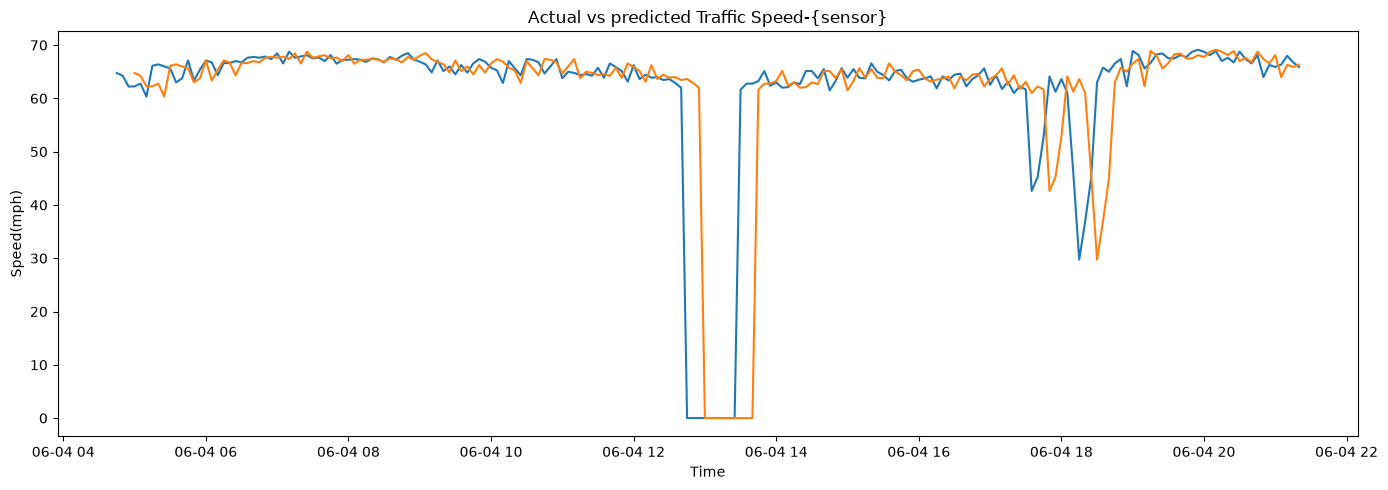

In [ ]:
import matplotlib.pyplot as plt
sensor=test_df.columns[0]
plt.figure(figsize=(14,5))

plt.plot(test_df.index[:200],test_df[sensor].iloc[:200],label="Actual Speed")
plt.plot(persistence_15.index[:200],persistence_15[sensor].iloc[:200],label="15 min Persistence Prediction")

plt.xlabel("Time")
plt.ylabel("Speed(mph)")
plt.title("Actual vs predicted Traffic Speed-{sensor}")

plt.tight_layout()
plt.show()


In [32]:
%pip install osmnx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt

In [38]:
place="Bengaluru, Karnataka, India"
G=ox.graph_from_point(
    (12.9352, 77.6245),
    dist=500,network_type="drive"
)

In [41]:
print(len(G.nodes))
print(len(G.edges))

245
580


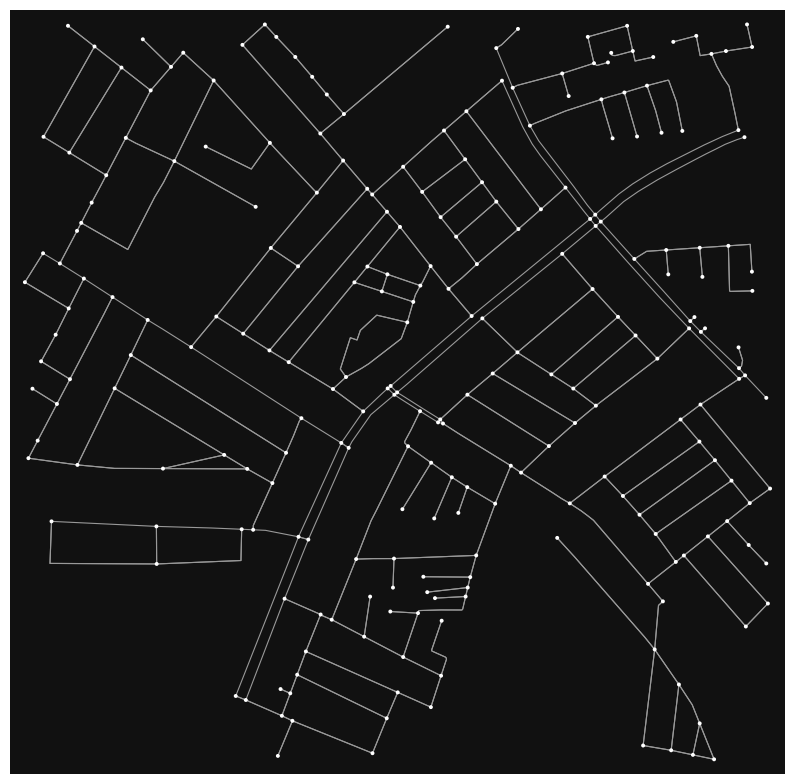

In [44]:
fig,ax=ox.plot_graph(
    G,
    node_size=8,
    edge_linewidth=0.8,
    figsize=(10,10)
)
plt.show()

In [ ]:
edges=ox.graph_to_gdfs(G,nodes=False)
edges[["length","highway"]].head()
#u,v,key together identify an edge

length      highway
u         v           key                         
17327139  309593057   0     50.303992  residential
          14206154055 0     44.938027      primary
254920166 1615723287  0     13.649908     tertiary
          308918179   0     61.557449     tertiary
          254920223   0    138.011290      primary

In [47]:
print("Average road length:", edges["length"].mean(), "metres")
print("Longest road segment:", edges["length"].max(), "metres")
print("Shortest road segment:", edges["length"].min(), "metres")

Average road length: 63.56984299421777 metres
Longest road segment: 245.4309237964582 metres
Shortest road segment: 4.815690999357105 metres


In [1]:
import shutil

print("SUMO:", shutil.which("sumo"))
print("SUMO-GUI:", shutil.which("sumo-gui"))

SUMO: C:\Program Files (x86)\SUMO\bin\sumo.EXE
SUMO-GUI: C:\Program Files (x86)\SUMO\bin\sumo-gui.EXE


In [2]:
!sumo --version

Eclipse SUMO sumo 1.28.0
 Build features: Windows-10.0.17763 AMD64 MSVC 19.51.36256.0 Release FMI Proj GUI FMT Intl SWIG Parquet Eigen
 Copyright (C) 2001-2026 German Aerospace Center (DLR) and others; https://sumo.dlr.de

Eclipse SUMO sumo 1.28.0 is part of SUMO.
This program and the accompanying materials
are made available under the terms of the Eclipse Public License v2.0
which accompanies this distribution, and is available at
http://www.eclipse.org/legal/epl-v20.html
This program may also be made available under the following Secondary
Licenses when the conditions for such availability set forth in the Eclipse
Public License 2.0 are satisfied: GNU General Public License, version 2
or later which is available at
https://www.gnu.org/licenses/old-licenses/gpl-2.0-standalone.html
SPDX-License-Identifier: EPL-2.0 OR GPL-2.0-or-later


In [4]:
!sumo-gui